# Part-4: Machine Learning for Time Series (RF, SVM, XGBoost)

**Time Series in Machine Learning** — Daneshkar.net

---


In [ ]:
# Install required packages (uncomment if needed)
# %pip install numpy
# %pip install pandas
# %pip install matplotlib
# %pip install statsmodels
# %pip install scipy
# %pip install scikit-learn
# %pip install xgboost

# Or install all at once:
# %pip install numpy pandas matplotlib statsmodels scipy scikit-learn xgboost


In [1]:
# Common imports & Jupyter setup
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os, warnings
warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 100
print("Setup complete! Ready to run.")


Setup complete! Ready to run.


---
## Feature Engineering


In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

warnings.filterwarnings('ignore')

OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)
np.random.seed(42)


## 1. GENERATE SYNTHETIC TIME SERIES DATA


In [4]:
print("=" * 60)
print("FEATURE ENGINEERING FOR TIME SERIES")
print("=" * 60)
np.random.seed(42)

n_points = 500
date_range = pd.date_range('2022-01-01', periods=n_points, freq='D')
t = np.arange(n_points)

trend = 0.05 * t
seasonality = 5 * np.sin(2 * np.pi * t / 30) + 3 * np.sin(2 * np.pi * t / 365)
noise = np.random.normal(0, 1.5, n_points)
values = 100 + trend + seasonality + noise

df = pd.DataFrame({'value': values}, index=date_range)
df.index.name = 'date'

print(f"\nData shape: {df.shape}")
print(f"Date range: {df.index[0].date()} to {df.index[-1].date()}")
print(f"Value range: {df['value'].min():.2f} to {df['value'].max():.2f}")


FEATURE ENGINEERING FOR TIME SERIES

Data shape: (500, 1)
Date range: 2022-01-01 to 2023-05-15
Value range: 95.20 to 134.47


## 2. DATA LEAKAGE DEMONSTRATION


In [5]:
print("\n" + "=" * 60)
print("DATA LEAKAGE DEMONSTRATION")
print("=" * 60)

# Incorrect approach: random shuffle (leaks future information)
wrong_split = int(len(df) * 0.8)
indices = np.arange(len(df))
np.random.shuffle(indices)
train_ids = indices[:wrong_split]
test_ids = indices[wrong_split:]

leaky_train = df.iloc[train_ids]
leaky_test = df.iloc[test_ids]

print("Incorrect split (random shuffle): future data leaks into training!")
print("  Train range:", leaky_train.index.min().date(), "to", leaky_train.index.max().date())
print("  Test range:", leaky_test.index.min().date(), "to", leaky_test.index.max().date())
print("  -> Test dates INTERLEAVE with train dates (leakage)")

# Correct approach: temporal split
correct_split_idx = int(len(df) * 0.8)
train_correct = df.iloc[:correct_split_idx]
test_correct = df.iloc[correct_split_idx:]

print("\nCorrect split (temporal): no future information leaked.")
print("  Train range:", train_correct.index[0].date(), "to", train_correct.index[-1].date())
print("  Test range:", test_correct.index[0].date(), "to", test_correct.index[-1].date())
print("  -> All train dates BEFORE all test dates (no leakage)")



DATA LEAKAGE DEMONSTRATION
Incorrect split (random shuffle): future data leaks into training!
  Train range: 2022-01-02 to 2023-05-15
  Test range: 2022-01-01 to 2023-05-14
  -> Test dates INTERLEAVE with train dates (leakage)

Correct split (temporal): no future information leaked.
  Train range: 2022-01-01 to 2023-02-04
  Test range: 2023-02-05 to 2023-05-15
  -> All train dates BEFORE all test dates (no leakage)


## 3. FEATURE ENGINEERING


In [6]:
print("\n" + "=" * 60)
print("FEATURE ENGINEERING")
print("=" * 60)

df_feat = df.copy()

# --- 3a. Lag features ---
lags = [1, 2, 3, 7, 14, 30]
for lag in lags:
    df_feat[f'lag_{lag}'] = df_feat['value'].shift(lag)

print(f"\nCreated {len(lags)} lag features: {lags}")

# --- 3b. Rolling window features ---
windows = [7, 14, 30]
for w in windows:
    roll = df_feat['value'].shift(1).rolling(w)
    df_feat[f'rmean_{w}'] = roll.mean()
    df_feat[f'rstd_{w}'] = roll.std()
    df_feat[f'rmin_{w}'] = roll.min()
    df_feat[f'rmax_{w}'] = roll.max()
    df_feat[f'rrange_{w}'] = df_feat[f'rmax_{w}'] - df_feat[f'rmin_{w}']

n_window_features = len(windows) * 5
print(f"Created {n_window_features} rolling window features for windows: {windows}")

# --- 3c. Difference features ---
diff_periods = [1, 7]
for p in diff_periods:
    df_feat[f'diff_{p}'] = df_feat['value'].diff(p)
    df_feat[f'pct_change_{p}'] = df_feat['value'].pct_change(p) * 100

print(f"Created {len(diff_periods) * 2} difference features")

# --- 3d. Datetime features ---
dt = df_feat.index
df_feat['year'] = dt.year
df_feat['month'] = dt.month
df_feat['day'] = dt.day
df_feat['day_of_week'] = dt.dayofweek
df_feat['day_of_year'] = dt.dayofyear
df_feat['quarter'] = dt.quarter
df_feat['is_weekend'] = dt.dayofweek.isin([5, 6]).astype(int)
df_feat['is_month_start'] = (dt.day == 1).astype(int)
df_feat['is_month_end'] = (dt.day == dt.days_in_month).astype(int)

# Cyclical encoding (sin/cos) - critical for preserving circular relationships
df_feat['month_sin'] = np.sin(2 * np.pi * dt.month / 12)
df_feat['month_cos'] = np.cos(2 * np.pi * dt.month / 12)
df_feat['dow_sin'] = np.sin(2 * np.pi * dt.dayofweek / 7)
df_feat['dow_cos'] = np.cos(2 * np.pi * dt.dayofweek / 7)
df_feat['doy_sin'] = np.sin(2 * np.pi * dt.dayofyear / 365)
df_feat['doy_cos'] = np.cos(2 * np.pi * dt.dayofyear / 365)

print("Created datetime features: year, month, day, day_of_week, quarter, weekend flags, cyclical sin/cos")

# --- 3e. Create target (next step forecast) ---
df_feat['target'] = df_feat['value'].shift(-1)

# Drop NaN rows
df_clean = df_feat.dropna().copy()
print(f"\nTotal samples after feature creation: {len(df_clean)}")
print(f"Total features: {df_clean.shape[1] - 2} (excluding 'value' and 'target')")

# Separate features and target
feature_cols = [c for c in df_clean.columns if c not in ['value', 'target']]
X = df_clean[feature_cols]
y = df_clean['target']



FEATURE ENGINEERING

Created 6 lag features: [1, 2, 3, 7, 14, 30]
Created 15 rolling window features for windows: [7, 14, 30]
Created 4 difference features
Created datetime features: year, month, day, day_of_week, quarter, weekend flags, cyclical sin/cos

Total samples after feature creation: 469
Total features: 40 (excluding 'value' and 'target')


## 4. FEATURE CORRELATION ANALYSIS



FEATURE CORRELATION ANALYSIS

Top 10 features correlated with target:
  lag_30              : +0.9521
  lag_1               : +0.9478
  lag_2               : +0.9271
  lag_3               : +0.8963
  rmean_7             : +0.8839
  rmax_7              : +0.8782
  rmin_7              : +0.8724
  rmin_30             : +0.8723
  rmean_30            : +0.8716
  rmax_30             : +0.8594
Saved: feature_correlation_heatmap.png


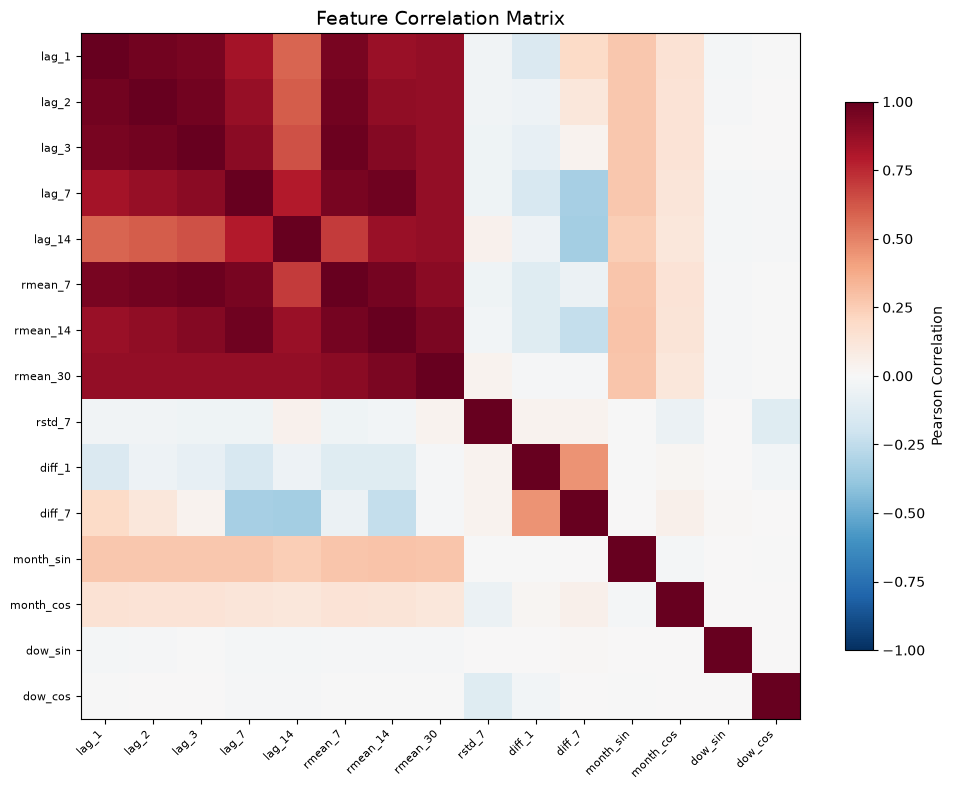

In [7]:
print("\n" + "=" * 60)
print("FEATURE CORRELATION ANALYSIS")
print("=" * 60)

corr_with_target = X.corrwith(y).sort_values(key=abs, ascending=False)
print("\nTop 10 features correlated with target:")
for feat, corr_val in corr_with_target.head(10).items():
    print(f"  {feat:20s}: {corr_val:+.4f}")

# Correlation heatmap (for a subset of features)
corr_features = ['lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14',
                 'rmean_7', 'rmean_14', 'rmean_30',
                 'rstd_7', 'diff_1', 'diff_7',
                 'month_sin', 'month_cos', 'dow_sin', 'dow_cos']

available_corr_features = [f for f in corr_features if f in X.columns]
if len(available_corr_features) > 1:
    fig, ax = plt.subplots(figsize=(10, 8))
    corr_matrix = X[available_corr_features].corr()
    im = ax.imshow(corr_matrix, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
    ax.set_xticks(range(len(available_corr_features)))
    ax.set_yticks(range(len(available_corr_features)))
    ax.set_xticklabels(available_corr_features, rotation=45, ha='right', fontsize=8)
    ax.set_yticklabels(available_corr_features, fontsize=8)
    ax.set_title('Feature Correlation Matrix', fontsize=14)
    cbar = fig.colorbar(im, ax=ax, shrink=0.8)
    cbar.set_label('Pearson Correlation')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'feature_correlation_heatmap.png'), dpi=150)
    print("Saved: feature_correlation_heatmap.png")


## 5. CYCLICAL FEATURES VISUALIZATION



CYCLICAL FEATURES VISUALIZATION
Saved: cyclical_features.png


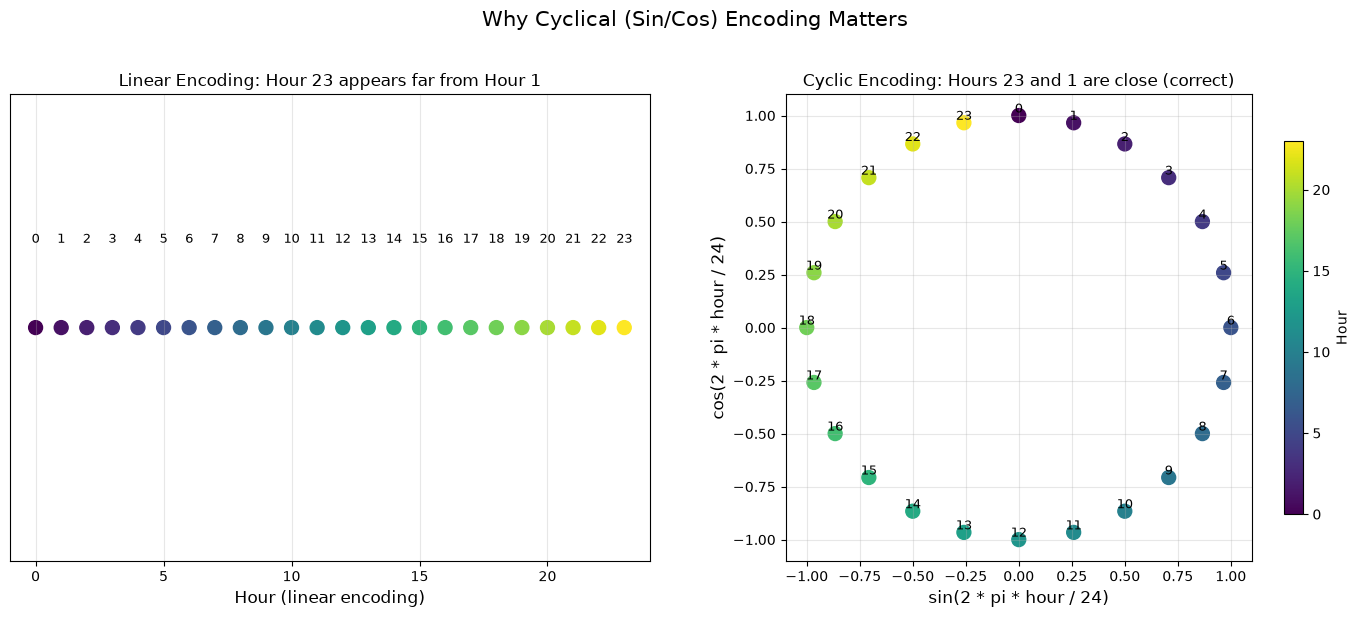

In [8]:
print("\n" + "=" * 60)
print("CYCLICAL FEATURES VISUALIZATION")
print("=" * 60)

# Show why sin/cos encoding is important
hours = np.arange(24)
hour_sin = np.sin(2 * np.pi * hours / 24)
hour_cos = np.cos(2 * np.pi * hours / 24)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: linear encoding (misleading distance)
ax = axes[0]
ax.scatter(hours, np.zeros_like(hours), c=hours, cmap='viridis', s=100)
for h in hours:
    ax.annotate(str(h), (h, 0.02), ha='center', fontsize=9)
ax.set_xlabel('Hour (linear encoding)', fontsize=12)
ax.set_title('Linear Encoding: Hour 23 appears far from Hour 1', fontsize=12)
ax.set_yticks([])
ax.set_xlim(-1, 24)
ax.grid(True, alpha=0.3)

# Right: cyclic encoding (correct circular distance)
ax = axes[1]
sc = ax.scatter(hour_sin, hour_cos, c=hours, cmap='viridis', s=100)
for h in range(24):
    ax.annotate(str(h), (hour_sin[h], hour_cos[h]), ha='center', va='bottom', fontsize=9)
ax.set_aspect('equal')
ax.set_xlabel('sin(2 * pi * hour / 24)', fontsize=12)
ax.set_ylabel('cos(2 * pi * hour / 24)', fontsize=12)
ax.set_title('Cyclic Encoding: Hours 23 and 1 are close (correct)', fontsize=12)
ax.grid(True, alpha=0.3)
cbar = fig.colorbar(sc, ax=ax, label='Hour', shrink=0.8)

fig.suptitle('Why Cyclical (Sin/Cos) Encoding Matters', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'cyclical_features.png'), dpi=150)
print("Saved: cyclical_features.png")


## 6. TIME-BASED TRAIN/TEST SPLIT VISUALIZATION



TRAIN/TEST SPLIT VISUALIZATION
Saved: data_leakage_demo.png


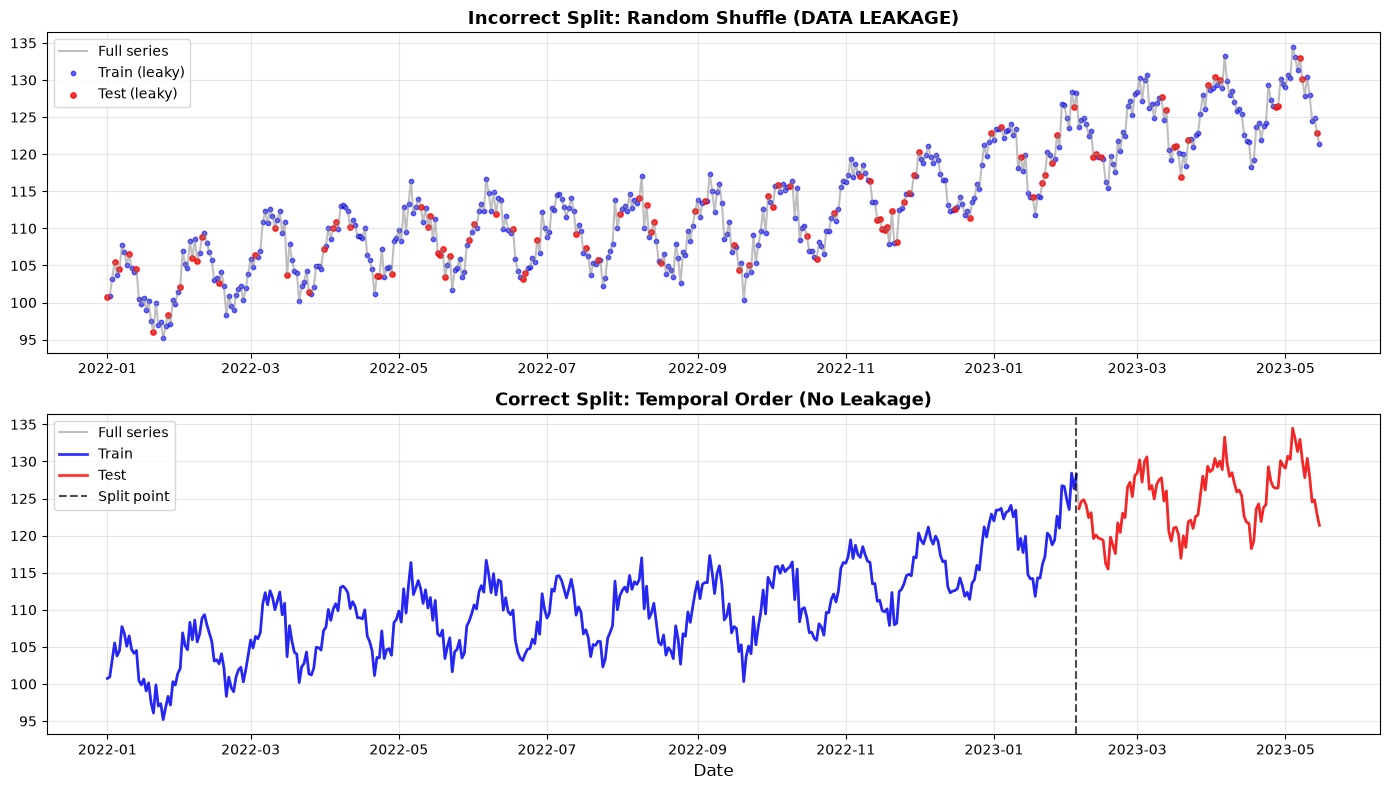

In [9]:
print("\n" + "=" * 60)
print("TRAIN/TEST SPLIT VISUALIZATION")
print("=" * 60)

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Top: incorrect random split (data leakage)
ax = axes[0]
ax.plot(df.index, df['value'], 'gray', alpha=0.5, label='Full series')
train_mask = np.zeros(len(df), dtype=bool)
train_mask[train_ids] = True
test_mask = np.zeros(len(df), dtype=bool)
test_mask[test_ids] = True
ax.scatter(df.index[train_mask], df['value'][train_mask],
           c='blue', s=10, alpha=0.6, label='Train (leaky)')
ax.scatter(df.index[test_mask], df['value'][test_mask],
           c='red', s=15, alpha=0.8, label='Test (leaky)')
ax.set_title('Incorrect Split: Random Shuffle (DATA LEAKAGE)', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# Bottom: correct temporal split
ax = axes[1]
ax.plot(df.index, df['value'], 'gray', alpha=0.5, label='Full series')
ax.plot(train_correct.index, train_correct['value'],
        'blue', linewidth=2, alpha=0.8, label='Train')
ax.plot(test_correct.index, test_correct['value'],
        'red', linewidth=2, alpha=0.8, label='Test')
ax.axvline(x=train_correct.index[-1], color='black', linestyle='--', alpha=0.7, label='Split point')
ax.set_title('Correct Split: Temporal Order (No Leakage)', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_xlabel('Date', fontsize=12)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'data_leakage_demo.png'), dpi=150)
print("Saved: data_leakage_demo.png")


---
## Random Forest


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error

warnings.filterwarnings('ignore')

OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)
np.random.seed(42)


## 1. GENERATE SYNTHETIC TIME SERIES DATA


In [2]:
print("=" * 60)
print("RANDOM FOREST FOR TIME SERIES FORECASTING")
print("=" * 60)
np.random.seed(42)

n_points = 500
date_range = pd.date_range('2022-01-01', periods=n_points, freq='D')
t = np.arange(n_points)

trend = 0.05 * t
seasonal_7 = 3 * np.sin(2 * np.pi * t / 7)
seasonal_30 = 5 * np.sin(2 * np.pi * t / 30)
noise = np.random.normal(0, 1.5, n_points)
values = 100 + trend + seasonal_7 + seasonal_30 + noise

df = pd.DataFrame({'value': values}, index=date_range)
df.index.name = 'date'

print(f"Data points: {n_points}")
print(f"Date range: {df.index[0].date()} to {df.index[-1].date()}")


RANDOM FOREST FOR TIME SERIES FORECASTING
Data points: 500
Date range: 2022-01-01 to 2023-05-15


## 2. PREPARE TIME SERIES FOR ML (LAG + WINDOW FEATURES)


In [4]:
print("\n" + "-" * 60)
print("FEATURE PREPARATION")
print("-" * 60)


def prepare_features(df, target_col, lags, windows):
    """Convert time series to supervised learning format."""
    df = df.copy()

    # Lag features
    for lag in lags:
        df[f'lag_{lag}'] = df[target_col].shift(lag)

    # Rolling window features (using shift(1) to avoid look-ahead bias)
    for w in windows:
        roll = df[target_col].shift(1).rolling(w)
        df[f'rmean_{w}'] = roll.mean()
        df[f'rstd_{w}'] = roll.std()
        df[f'rmin_{w}'] = roll.min()
        df[f'rmax_{w}'] = roll.max()

    # Difference features
    df['diff_1'] = df[target_col].diff(1)
    df['diff_7'] = df[target_col].diff(7)

    # Target: next step
    df['target'] = df[target_col].shift(-1)

    # Drop NaN rows
    df_clean = df.dropna()

    return df_clean


lags = [1, 2, 3, 7, 14, 30]
windows = [7, 14, 30]

df_prep = prepare_features(df, 'value', lags, windows)

feature_cols = [c for c in df_prep.columns if c not in ['value', 'target']]
X = df_prep[feature_cols]
y = df_prep['target']

print(f"Features: {len(feature_cols)}")
print(f"Samples:  {len(X)}")
print(f"Feature names: {feature_cols}")

# Temporal split
split_idx = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Train: {len(X_train)} samples, Test: {len(X_test)} samples")



------------------------------------------------------------
FEATURE PREPARATION
------------------------------------------------------------
Features: 20
Samples:  469
Feature names: ['lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_30', 'rmean_7', 'rstd_7', 'rmin_7', 'rmax_7', 'rmean_14', 'rstd_14', 'rmin_14', 'rmax_14', 'rmean_30', 'rstd_30', 'rmin_30', 'rmax_30', 'diff_1', 'diff_7']
Train: 375 samples, Test: 94 samples


## 3. BASELINE RANDOM FOREST


In [5]:
print("\n" + "-" * 60)
print("BASELINE RANDOM FOREST")
print("-" * 60)

rf_base = RandomForestRegressor(n_estimators=200, max_depth=10,
                                min_samples_leaf=5, random_state=42, n_jobs=-1)
rf_base.fit(X_train, y_train)

y_pred_base = rf_base.predict(X_test)
rmse_base = np.sqrt(mean_squared_error(y_test, y_pred_base))
mae_base = mean_absolute_error(y_test, y_pred_base)

print(f"Baseline RF - RMSE: {rmse_base:.4f}, MAE: {mae_base:.4f}")



------------------------------------------------------------
BASELINE RANDOM FOREST
------------------------------------------------------------
Baseline RF - RMSE: 3.4105, MAE: 2.7602


## 4. HYPERPARAMETER TUNING WITH TimeSeriesSplit


In [ ]:
print("\n" + "-" * 60)
print("HYPERPARAMETER TUNING (RandomizedSearchCV + TimeSeriesSplit)")
print("-" * 60)

param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [5, 7, 10, 15, 20, None],
    'min_samples_leaf': [1, 3, 5, 10, 20],
    'min_samples_split': [2, 5, 10],
    'max_features': ['sqrt', 'log2', 0.5, 0.8]
}

rf_tune = RandomForestRegressor(random_state=42, n_jobs=-1)
tscv = TimeSeriesSplit(n_splits=3)

search = RandomizedSearchCV(
    rf_tune,
    param_distributions=param_dist,
    n_iter=30,
    cv=tscv,
    scoring='neg_mean_squared_error',
    random_state=42,
    n_jobs=-1,
    verbose=0
)

search.fit(X_train, y_train)

best_rf = search.best_estimator_
print("\nBest hyperparameters:")
for param, value in search.best_params_.items():
    print(f"  {param}: {value}")
print(f"Best CV score (neg MSE): {search.best_score_:.4f}")

# Evaluate tuned model
y_pred_tuned = best_rf.predict(X_test)
rmse_tuned = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
mae_tuned = mean_absolute_error(y_test, y_pred_tuned)
print(f"\nTuned RF - RMSE: {rmse_tuned:.4f}, MAE: {mae_tuned:.4f}")
print(f"Improvement: RMSE {(rmse_base - rmse_tuned) / rmse_base * 100:.1f}% better")



------------------------------------------------------------
HYPERPARAMETER TUNING (RandomizedSearchCV + TimeSeriesSplit)
------------------------------------------------------------

Best hyperparameters:
  n_estimators: 100
  min_samples_split: 5
  min_samples_leaf: 5
  max_features: 0.5
  max_depth: 10
Best CV score (neg MSE): -18.8060

Tuned RF - RMSE: 3.6669, MAE: 2.9932
Improvement: RMSE -7.5% better


## 5. TIME SERIES CROSS-VALIDATION


In [7]:
print("\n" + "-" * 60)
print("TIME SERIES CROSS-VALIDATION")
print("-" * 60)

tscv_full = TimeSeriesSplit(n_splits=5)
cv_scores = []
all_predictions = []

for fold, (train_idx, test_idx) in enumerate(tscv_full.split(X)):
    X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
    y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]

    rf_cv = RandomForestRegressor(**search.best_params_, random_state=42, n_jobs=-1)
    rf_cv.fit(X_tr, y_tr)
    y_pred_cv = rf_cv.predict(X_te)

    rmse_cv = np.sqrt(mean_squared_error(y_te, y_pred_cv))
    mae_cv = mean_absolute_error(y_te, y_pred_cv)

    cv_scores.append({'fold': fold + 1, 'RMSE': rmse_cv, 'MAE': mae_cv,
                      'train_size': len(X_tr), 'test_size': len(X_te)})
    all_predictions.append({'y_true': y_te, 'y_pred': y_pred_cv, 'fold': fold + 1})

cv_results = pd.DataFrame(cv_scores)
print("\nCross-validation results:")
print(cv_results.to_string(index=False))
print(f"\nMean RMSE: {cv_results['RMSE'].mean():.4f} +/- {cv_results['RMSE'].std():.4f}")
print(f"Mean MAE:  {cv_results['MAE'].mean():.4f} +/- {cv_results['MAE'].std():.4f}")



------------------------------------------------------------
TIME SERIES CROSS-VALIDATION
------------------------------------------------------------

Cross-validation results:
 fold     RMSE      MAE  train_size  test_size
    1 3.996881 3.183446          79         78
    2 3.649925 2.982131         157         78
    3 4.192116 3.591517         235         78
    4 4.231861 3.514287         313         78
    5 3.968578 3.231667         391         78

Mean RMSE: 4.0079 +/- 0.2313
Mean MAE:  3.3006 +/- 0.2501


## 6. RECURSIVE MULTI-STEP FORECASTING


In [9]:
print("\n" + "-" * 60)
print("RECURSIVE MULTI-STEP FORECASTING")
print("-" * 60)


def recursive_forecast(model, last_values, lags, windows, n_steps):
    """
    Recursive forecasting: each prediction becomes input for the next step.
    """
    forecasts = []
    current_series = list(last_values)

    for step in range(n_steps):
        # Build feature vector from current series
        features = {}
        for lag in lags:
            if lag <= len(current_series):
                features[f'lag_{lag}'] = current_series[-lag]
            else:
                features[f'lag_{lag}'] = current_series[0]

        prev_vals = np.array(current_series)

        for w in windows:
            if len(prev_vals) >= w + 1:
                window_data = prev_vals[-(w + 1):-1]
            else:
                window_data = prev_vals[:-1]

            if len(window_data) > 0:
                features[f'rmean_{w}'] = np.mean(window_data)
                features[f'rstd_{w}'] = np.std(window_data)
                features[f'rmin_{w}'] = np.min(window_data)
                features[f'rmax_{w}'] = np.max(window_data)
            else:
                features[f'rmean_{w}'] = 0
                features[f'rstd_{w}'] = 0
                features[f'rmin_{w}'] = 0
                features[f'rmax_{w}'] = 0

        if len(prev_vals) >= 2:
            features['diff_1'] = prev_vals[-1] - prev_vals[-2]
        else:
            features['diff_1'] = 0

        if len(prev_vals) >= 8:
            features['diff_7'] = prev_vals[-1] - prev_vals[-8]
        else:
            features['diff_7'] = 0

        feat_df = pd.DataFrame([features])
        feat_df = feat_df[feature_cols]

        pred = model.predict(feat_df)[0]
        forecasts.append(pred)
        current_series.append(pred)

    return np.array(forecasts)


# Use the last 30 known values to forecast 14 steps ahead
last_known = df['value'].values[-30:]
n_forecast_steps = 14
forecast = recursive_forecast(best_rf, last_known, lags, windows, n_forecast_steps)

print(f"Recursive forecast for {n_forecast_steps} steps ahead:")
for i, val in enumerate(forecast):
    print(f"  Step {i + 1:2d}: {val:.4f}")



------------------------------------------------------------
RECURSIVE MULTI-STEP FORECASTING
------------------------------------------------------------
Recursive forecast for 14 steps ahead:
  Step  1: 120.4754
  Step  2: 120.5045
  Step  3: 120.4847
  Step  4: 119.3327
  Step  5: 119.6696
  Step  6: 119.4462
  Step  7: 119.1470
  Step  8: 118.8194
  Step  9: 118.9759
  Step 10: 119.3986
  Step 11: 119.8638
  Step 12: 121.1144
  Step 13: 122.4624
  Step 14: 123.1640


## 7. PLOTS



------------------------------------------------------------
GENERATING PLOTS
------------------------------------------------------------
Saved: rf_forecast.png
Saved: rf_feature_importance.png
Saved: rf_recursive_forecast.png
Saved: rf_cv_scores.png


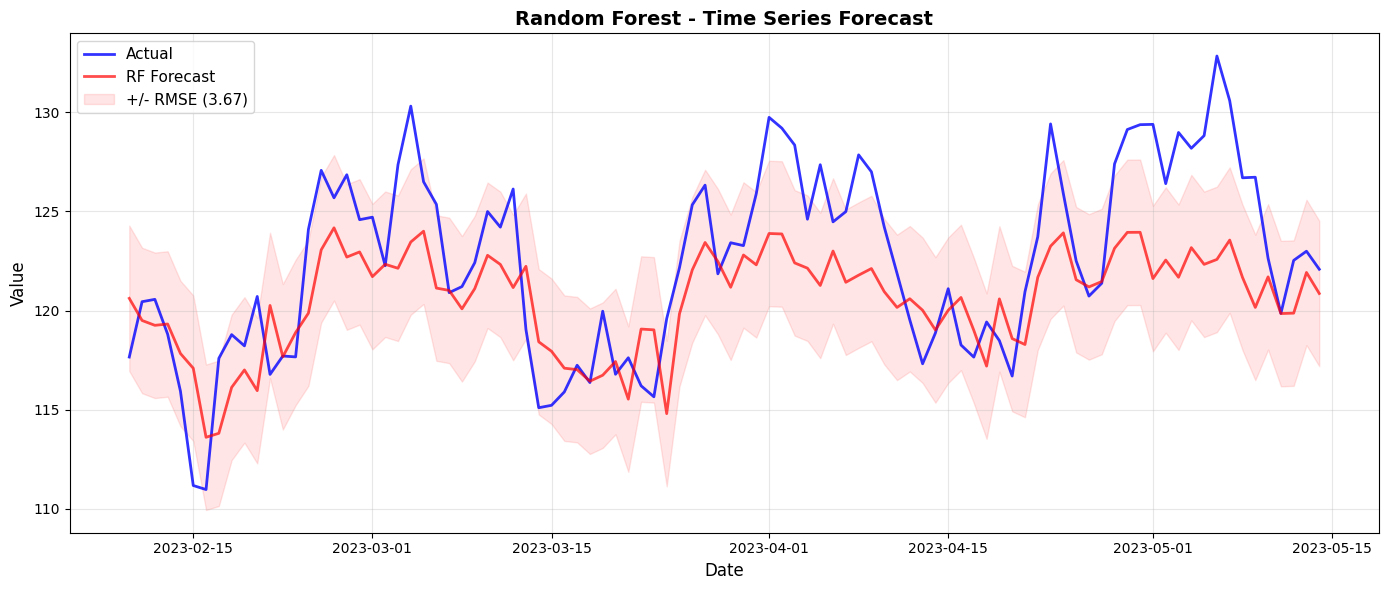

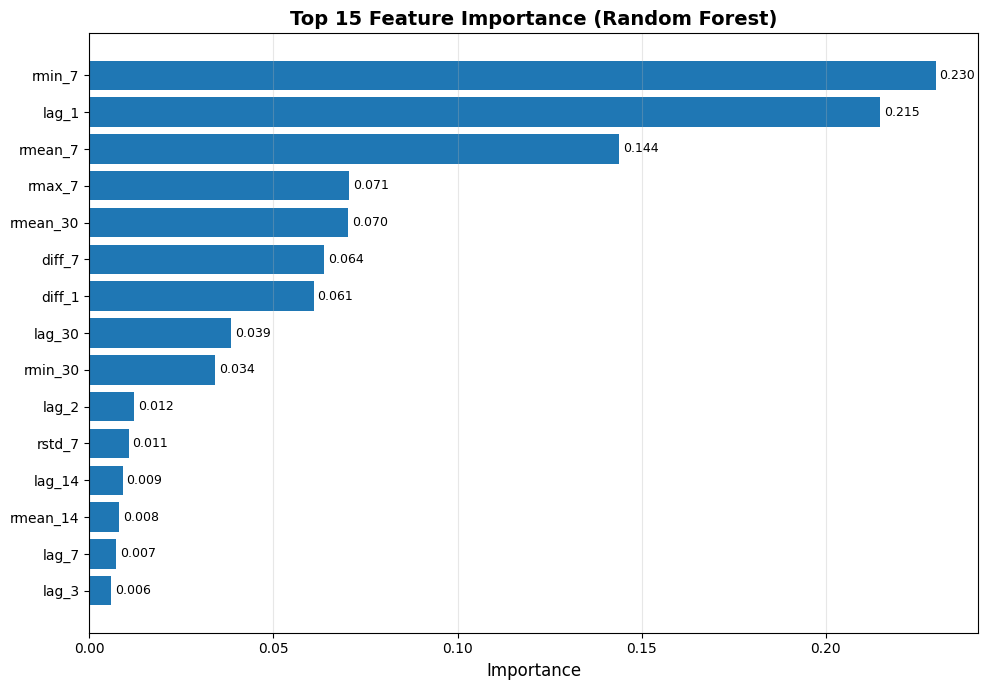

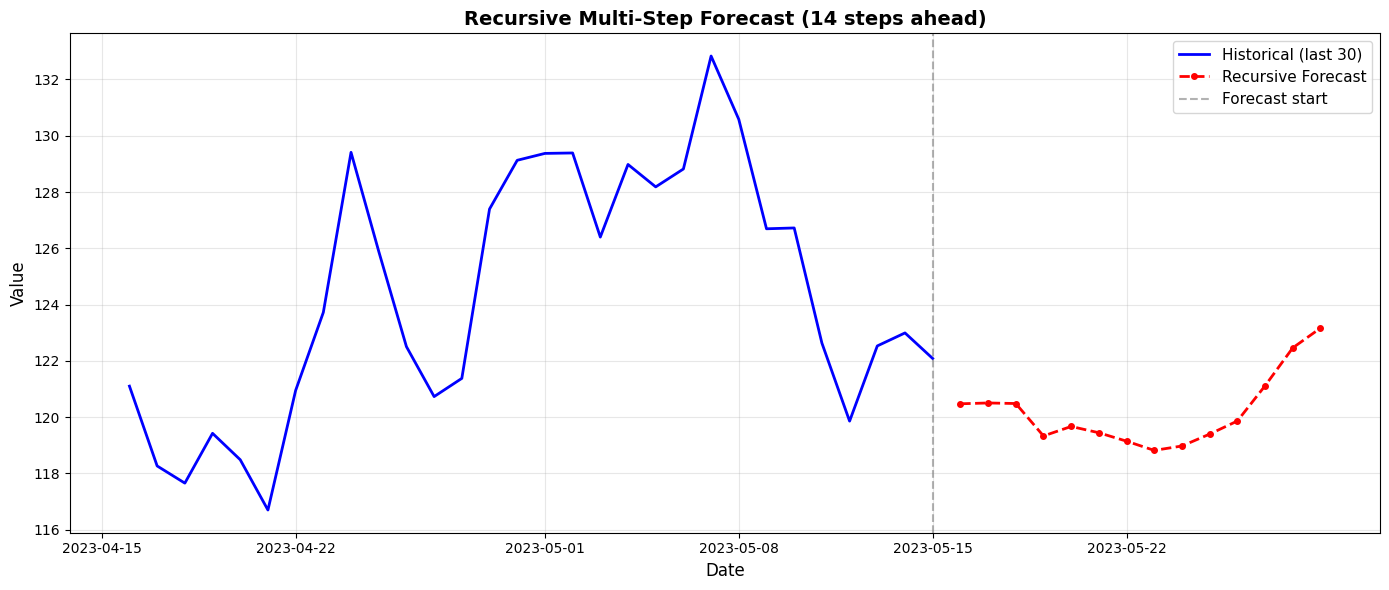

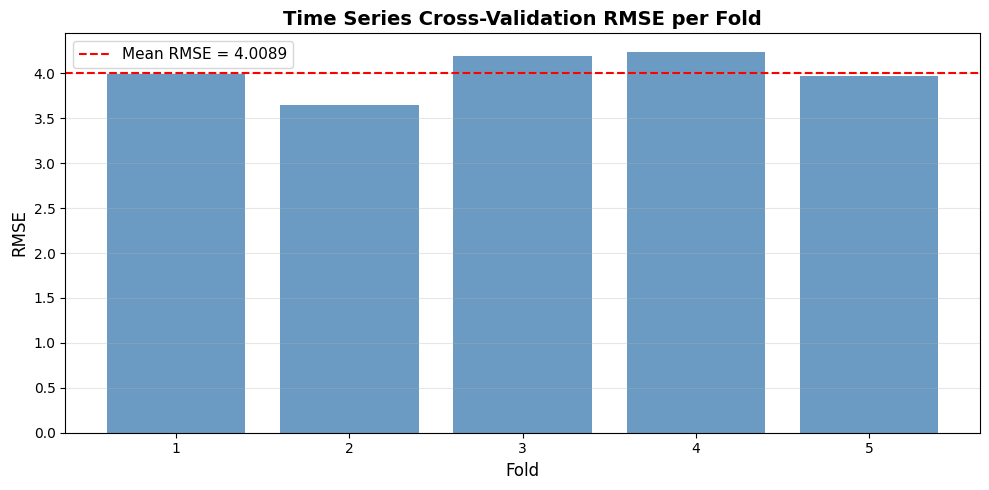

In [ ]:
print("\n" + "-" * 60)
print("GENERATING PLOTS")
print("-" * 60)

# 7a. Predictions vs actual
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(y_test.index, y_test.values, 'b-', linewidth=2, alpha=0.8, label='Actual')
ax.plot(y_test.index, y_pred_tuned, 'r-', linewidth=2, alpha=0.7, label='RF Forecast')
ax.fill_between(y_test.index,
                y_pred_tuned - rmse_tuned, y_pred_tuned + rmse_tuned,
                color='red', alpha=0.1, label=f'+/- RMSE ({rmse_tuned:.2f})')
ax.set_title('Random Forest - Time Series Forecast', fontsize=14, fontweight='bold')
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Value', fontsize=12)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'rf_forecast.png'), dpi=150)
print("Saved: rf_forecast.png")

# 7b. Feature importance
importance = pd.Series(best_rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
top_n = 15

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(range(top_n), importance.values[:top_n])
ax.set_yticks(range(top_n))
ax.set_yticklabels(importance.index[:top_n])
ax.invert_yaxis()
ax.set_xlabel('Importance', fontsize=12)
ax.set_title(f'Top {top_n} Feature Importance (Random Forest)', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, axis='x')

for i, (v, name) in enumerate(zip(importance.values[:top_n], importance.index[:top_n])):
    ax.text(v + 0.001, i, f'{v:.3f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'rf_feature_importance.png'), dpi=150)
print("Saved: rf_feature_importance.png")

# 7c. Recursive forecast visualization
future_dates = pd.date_range(start=df.index[-1] + pd.Timedelta(days=1),
                              periods=n_forecast_steps, freq='D')
historical_last_30 = df.index[-30:]

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(historical_last_30, df['value'].values[-30:],
        'b-', linewidth=2, label='Historical (last 30)')
ax.plot(future_dates, forecast, 'r--', linewidth=2, marker='o',
        markersize=4, label='Recursive Forecast')
ax.axvline(x=df.index[-1], color='gray', linestyle='--', alpha=0.6,
           label='Forecast start')
ax.set_title(f'Recursive Multi-Step Forecast ({n_forecast_steps} steps ahead)',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Value', fontsize=12)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'rf_recursive_forecast.png'), dpi=150)
print("Saved: rf_recursive_forecast.png")

# 7d. CV scores bar chart
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(cv_results['fold'], cv_results['RMSE'], color='steelblue', alpha=0.8)
ax.set_xlabel('Fold', fontsize=12)
ax.set_ylabel('RMSE', fontsize=12)
ax.set_title('Time Series Cross-Validation RMSE per Fold', fontsize=14, fontweight='bold')
ax.set_xticks(cv_results['fold'])
ax.axhline(y=cv_results['RMSE'].mean(), color='red', linestyle='--',
           label=f'Mean RMSE = {cv_results["RMSE"].mean():.4f}')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'rf_cv_scores.png'), dpi=150)
print("Saved: rf_cv_scores.png")


## 8. SUMMARY


In [ ]:
print("\n" + "=" * 60)
print("SUMMARY")
print("=" * 60)
print(f"Baseline RF  - RMSE: {rmse_base:.4f}, MAE: {mae_base:.4f}")
print(f"Tuned RF     - RMSE: {rmse_tuned:.4f}, MAE: {mae_tuned:.4f}")
print(f"CV Mean RMSE: {cv_results['RMSE'].mean():.4f} +/- {cv_results['RMSE'].std():.4f}")
print(f"Best params: {search.best_params_}")
print("\nAll plots saved to:", OUTPUT_DIR)



SUMMARY
Baseline RF  - RMSE: 3.4100, MAE: 2.7601
Tuned RF     - RMSE: 3.6669, MAE: 2.9932
CV Mean RMSE: 4.0089 +/- 0.2329
Best params: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': 10}

All plots saved to: c:\Users\gheir\Documents\GitHub1\Dox\TimeSeries\کد\Part-4


---
## SVM


In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error

warnings.filterwarnings('ignore')

OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)
np.random.seed(42)


## 1. GENERATE SYNTHETIC TIME SERIES DATA


In [ ]:
print("=" * 60)
print("SVR (SUPPORT VECTOR REGRESSION) FOR TIME SERIES")
print("=" * 60)

n_points = 400
date_range = pd.date_range('2022-01-01', periods=n_points, freq='D')
t = np.arange(n_points)

# Non-linear time series with trend + seasonality
trend = 0.08 * t
seasonal = 6 * np.sin(2 * np.pi * t / 40) + 3 * np.sin(2 * np.pi * t / 15)
noise = np.random.normal(0, 1.0, n_points)
values = 100 + trend + seasonal + noise

series = pd.Series(values, index=date_range, name='value')
df = pd.DataFrame(series)
df.index.name = 'date'

print(f"Data points: {n_points}")
print(f"Date range: {df.index[0].date()} to {df.index[-1].date()}")
print(f"Value range: {df['value'].min():.2f} to {df['value'].max():.2f}")


SVR (SUPPORT VECTOR REGRESSION) FOR TIME SERIES
Data points: 400
Date range: 2022-01-01 to 2023-02-04
Value range: 93.09 to 137.14


## 2. CREATE LAG FEATURES


In [ ]:
print("\n" + "-" * 60)
print("FEATURE PREPARATION")
print("-" * 60)

lags = [1, 2, 3, 7, 14, 21]
df_feat = df.copy()

for lag in lags:
    df_feat[f'lag_{lag}'] = df_feat['value'].shift(lag)

# Rolling features
for w in [7, 14]:
    roll = df_feat['value'].shift(1).rolling(w)
    df_feat[f'rmean_{w}'] = roll.mean()
    df_feat[f'rstd_{w}'] = roll.std()

# Target
df_feat['target'] = df_feat['value'].shift(-1)
df_clean = df_feat.dropna()

feature_cols = [c for c in df_clean.columns if c not in ['value', 'target']]
X = df_clean[feature_cols]
y = df_clean['target']

print(f"Features: {len(feature_cols)} -> {feature_cols}")
print(f"Samples:  {len(X)}")

# Temporal split
split_idx = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
print(f"Train: {len(X_train)}, Test: {len(X_test)}")



------------------------------------------------------------
FEATURE PREPARATION
------------------------------------------------------------
Features: 10 -> ['lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_21', 'rmean_7', 'rstd_7', 'rmean_14', 'rstd_14']
Samples:  378
Train: 302, Test: 76


## 3. FEATURE SCALING (MANDATORY FOR SVR)


In [ ]:
print("\n" + "-" * 60)
print("FEATURE SCALING WITH StandardScaler")
print("-" * 60)

scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).ravel()
y_test_2d = y_test.values.reshape(-1, 1)
y_test_scaled = scaler_y.transform(y_test_2d).ravel()

print("X_train: mean ~0, std ~1 (scaled)")
print(f"X_train mean: {X_train_scaled.mean():.6f}, std: {X_train_scaled.std():.6f}")



------------------------------------------------------------
FEATURE SCALING WITH StandardScaler
------------------------------------------------------------
X_train: mean ~0, std ~1 (scaled)
X_train mean: -0.000000, std: 1.000000


## 4. SVR WITH RBF KERNEL (BASELINE)


In [ ]:
print("\n" + "-" * 60)
print("SVR WITH RBF KERNEL")
print("-" * 60)

svr_rbf = SVR(kernel='rbf', C=1.0, epsilon=0.1, gamma='scale')
svr_rbf.fit(X_train_scaled, y_train_scaled)

y_pred_scaled = svr_rbf.predict(X_test_scaled)
y_pred_rbf = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()

rmse_rbf = np.sqrt(mean_squared_error(y_test, y_pred_rbf))
mae_rbf = mean_absolute_error(y_test, y_pred_rbf)
print(f"SVR (RBF) - RMSE: {rmse_rbf:.4f}, MAE: {mae_rbf:.4f}")
print(f"Support vectors: {sum(svr_rbf.n_support_)} ({sum(svr_rbf.n_support_) / len(X_train) * 100:.1f}% of training data)")



------------------------------------------------------------
SVR WITH RBF KERNEL
------------------------------------------------------------
SVR (RBF) - RMSE: 8.5268, MAE: 7.1216
Support vectors: 207 (68.5% of training data)


## 5. HYPERPARAMETER TUNING (C, epsilon, gamma)


In [ ]:
print("\n" + "-" * 60)
print("HYPERPARAMETER TUNING (C, epsilon, gamma)")
print("-" * 60)

param_dist = {
    'kernel': ['rbf'],
    'C': np.logspace(-2, 3, 12).tolist(),
    'epsilon': np.logspace(-3, 0, 10).tolist(),
    'gamma': ['scale', 'auto'] + np.logspace(-3, 2, 6).tolist()
}

svr_tune = SVR()
tscv_tune = TimeSeriesSplit(n_splits=3)

search = RandomizedSearchCV(
    svr_tune,
    param_distributions=param_dist,
    n_iter=30,
    cv=tscv_tune,
    scoring='neg_mean_squared_error',
    random_state=42,
    n_jobs=-1,
    verbose=0
)

search.fit(X_train_scaled, y_train_scaled)

print("\nBest SVR hyperparameters:")
for param, value in search.best_params_.items():
    print(f"  {param}: {value}")
print(f"Best CV score (neg MSE): {search.best_score_:.4f}")

# Evaluate tuned model
best_svr = search.best_estimator_
y_pred_best_scaled = best_svr.predict(X_test_scaled)
y_pred_best = scaler_y.inverse_transform(y_pred_best_scaled.reshape(-1, 1)).ravel()

rmse_best = np.sqrt(mean_squared_error(y_test, y_pred_best))
mae_best = mean_absolute_error(y_test, y_pred_best)
print(f"\nTuned SVR - RMSE: {rmse_best:.4f}, MAE: {mae_best:.4f}")



------------------------------------------------------------
HYPERPARAMETER TUNING (C, epsilon, gamma)
------------------------------------------------------------

Best SVR hyperparameters:
  kernel: rbf
  gamma: scale
  epsilon: 0.004641588833612777
  C: 15.199110829529332
Best CV score (neg MSE): -0.3213

Tuned SVR - RMSE: 10.2224, MAE: 8.4096


## 6. KERNEL COMPARISON


In [ ]:
print("\n" + "-" * 60)
print("KERNEL COMPARISON: Linear vs RBF vs Polynomial vs Sigmoid")
print("-" * 60)

kernels = {
    'Linear': SVR(kernel='linear', C=1.0, epsilon=0.1),
    'RBF': SVR(kernel='rbf', C=1.0, epsilon=0.1, gamma='scale'),
    'Polynomial (deg=3)': SVR(kernel='poly', C=1.0, epsilon=0.1, degree=3, gamma='scale'),
    'Sigmoid': SVR(kernel='sigmoid', C=1.0, epsilon=0.1, gamma='scale')
}

kernel_results = {}
kernel_predictions = {}

for name, model in kernels.items():
    model.fit(X_train_scaled, y_train_scaled)
    pred_s = model.predict(X_test_scaled)
    pred = scaler_y.inverse_transform(pred_s.reshape(-1, 1)).ravel()
    kernel_predictions[name] = pred

    rmse_k = np.sqrt(mean_squared_error(y_test, pred))
    mae_k = mean_absolute_error(y_test, pred)
    n_sv = sum(model.n_support_) if hasattr(model, 'n_support_') else 0
    kernel_results[name] = {'RMSE': rmse_k, 'MAE': mae_k, 'n_support': n_sv}

    print(f"  {name:22s}: RMSE={rmse_k:.4f}, MAE={mae_k:.4f}, "
          f"Support vectors={n_sv}")



------------------------------------------------------------
KERNEL COMPARISON: Linear vs RBF vs Polynomial vs Sigmoid
------------------------------------------------------------
  Linear                : RMSE=1.8161, MAE=1.4339, Support vectors=196
  RBF                   : RMSE=8.5268, MAE=7.1216, Support vectors=207
  Polynomial (deg=3)    : RMSE=11.9097, MAE=9.6249, Support vectors=231
  Sigmoid               : RMSE=237.5626, MAE=216.2479, Support vectors=300


## 7. SVRTimeSeries CLASS


In [ ]:
print("\n" + "-" * 60)
print("SVRTimeSeries CLASS DEMONSTRATION")
print("-" * 60)


class SVRTimeSeries:
    """
    Complete SVR wrapper for time series forecasting with automatic scaling.
    """

    def __init__(self, kernel='rbf', C=1.0, epsilon=0.1, gamma='scale', degree=3):
        self.model = SVR(kernel=kernel, C=C, epsilon=epsilon,
                         gamma=gamma, degree=degree)
        self.scaler_X = StandardScaler()
        self.scaler_y = StandardScaler()
        self.feature_names_ = None
        self.train_size_ = None

    def fit(self, X_train, y_train):
        """Fit SVR with automatic feature/target scaling."""
        self.feature_names_ = (X_train.columns.tolist()
                               if hasattr(X_train, 'columns') else None)
        self.train_size_ = len(X_train)

        X_scaled = self.scaler_X.fit_transform(X_train)
        y_values = (y_train.values if hasattr(y_train, 'values')
                    else y_train)
        y_scaled = self.scaler_y.fit_transform(
            y_values.reshape(-1, 1)
        ).ravel()

        self.model.fit(X_scaled, y_scaled)

        n_sv = sum(self.model.n_support_)
        sv_pct = n_sv / len(X_train) * 100
        print(f"  SVR fitted: {n_sv} support vectors ({sv_pct:.1f}% of data)")
        return self

    def predict(self, X):
        """Predict and inverse-transform to original scale."""
        X_scaled = self.scaler_X.transform(X)
        y_pred_scaled = self.model.predict(X_scaled)
        return self.scaler_y.inverse_transform(
            y_pred_scaled.reshape(-1, 1)
        ).ravel()

    def evaluate(self, X_test, y_test):
        """Evaluate model performance."""
        y_pred = self.predict(X_test)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        mae = mean_absolute_error(y_test, y_pred)
        mape = np.mean(np.abs((y_test.values - y_pred) / y_test.values)) * 100
        return {'RMSE': rmse, 'MAE': mae, 'MAPE': mape, 'predictions': y_pred}


# Demonstrate the class
svr_ts = SVRTimeSeries(kernel='rbf', C=search.best_params_.get('C', 10.0),
                       epsilon=search.best_params_.get('epsilon', 0.1),
                       gamma=search.best_params_.get('gamma', 'scale'))
svr_ts.fit(X_train, y_train)
eval_results = svr_ts.evaluate(X_test, y_test)
print(f"  SVRTimeSeries test - RMSE: {eval_results['RMSE']:.4f}, "
      f"MAE: {eval_results['MAE']:.4f}, MAPE: {eval_results['MAPE']:.2f}%")



------------------------------------------------------------
SVRTimeSeries CLASS DEMONSTRATION
------------------------------------------------------------
  SVR fitted: 297 support vectors (98.3% of data)
  SVRTimeSeries test - RMSE: 10.2224, MAE: 8.4096, MAPE: 6.43%


## 8. PLOTS



------------------------------------------------------------
GENERATING PLOTS
------------------------------------------------------------
Saved: svr_forecast.png
Saved: svr_kernel_comparison.png
Saved: svr_kernel_errors.png
Saved: svr_actual_vs_predicted.png


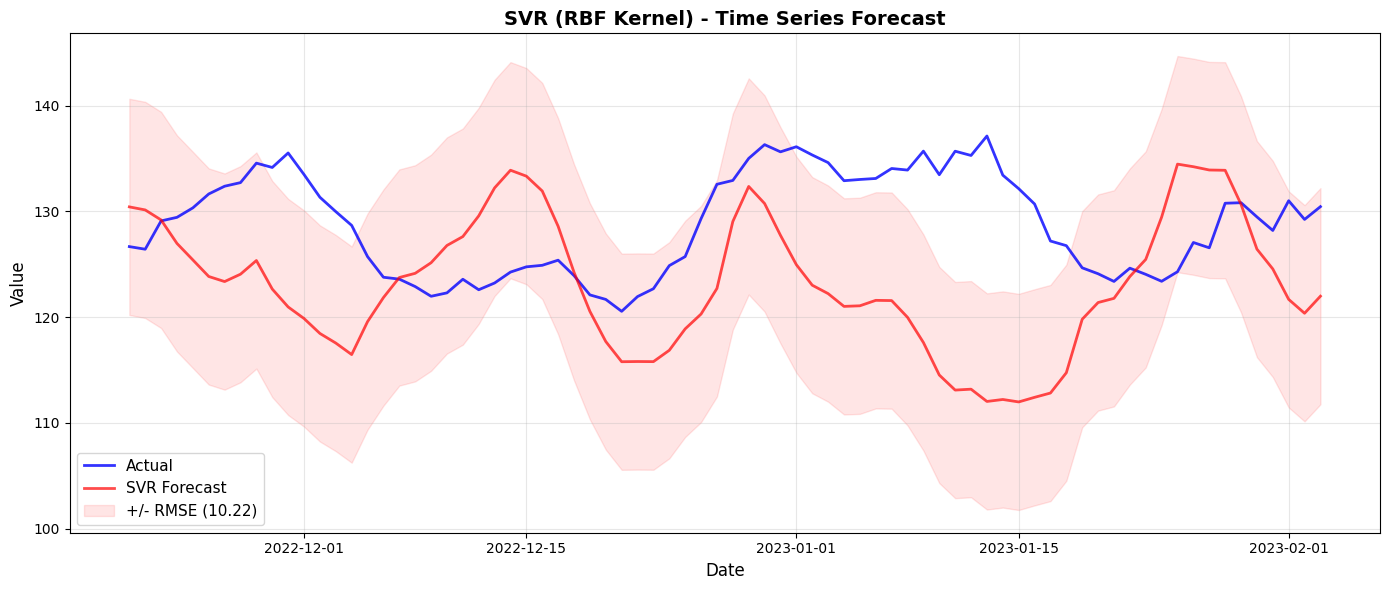

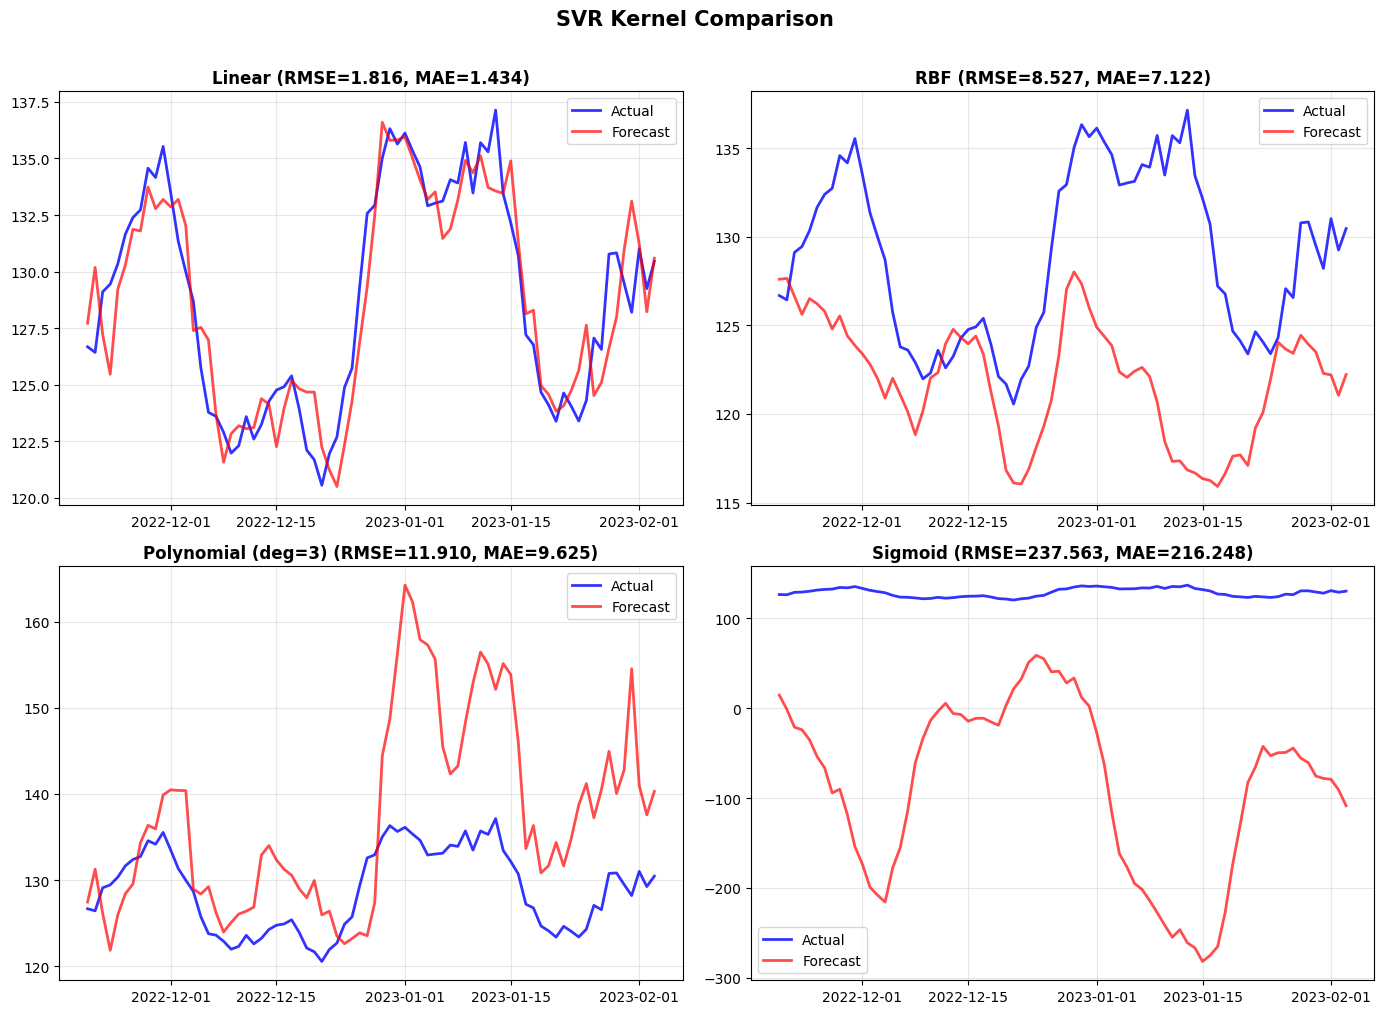

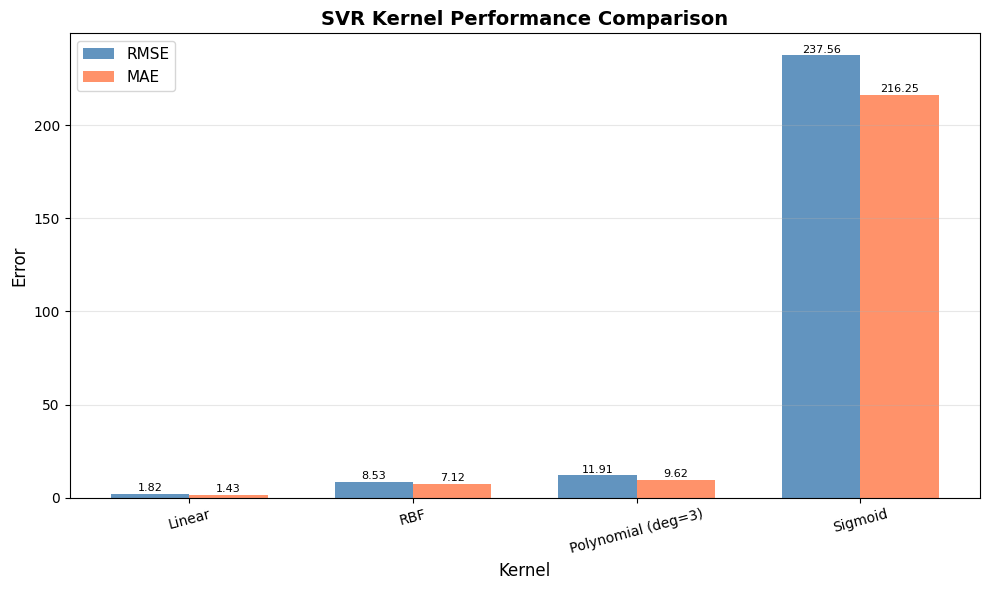

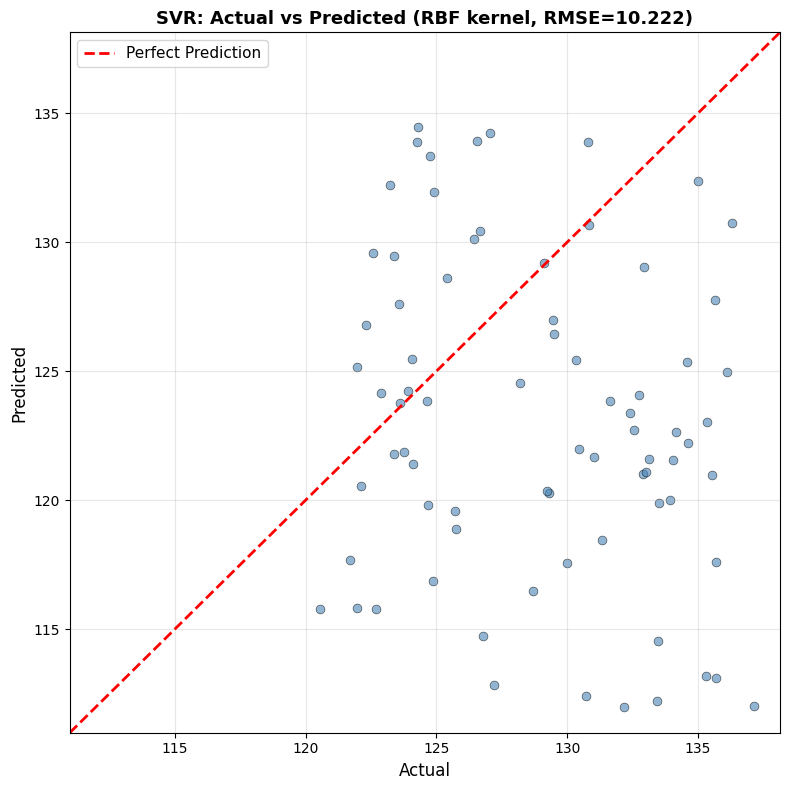

In [ ]:
print("\n" + "-" * 60)
print("GENERATING PLOTS")
print("-" * 60)

# 8a. Best SVR forecast vs actual
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(y_test.index, y_test.values, 'b-', linewidth=2, alpha=0.8, label='Actual')
ax.plot(y_test.index, y_pred_best, 'r-', linewidth=2, alpha=0.7, label='SVR Forecast')
ax.fill_between(y_test.index,
                y_pred_best - rmse_best, y_pred_best + rmse_best,
                color='red', alpha=0.1, label=f'+/- RMSE ({rmse_best:.2f})')
ax.set_title('SVR (RBF Kernel) - Time Series Forecast', fontsize=14, fontweight='bold')
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Value', fontsize=12)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'svr_forecast.png'), dpi=150)
print("Saved: svr_forecast.png")

# 8b. Kernel comparison plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
kernel_names_sorted = list(kernel_results.keys())

for ax, name in zip(axes.flat, kernel_names_sorted):
    ax.plot(y_test.index, y_test.values, 'b-', linewidth=2, alpha=0.8, label='Actual')
    ax.plot(y_test.index, kernel_predictions[name], 'r-', linewidth=2, alpha=0.7, label='Forecast')
    r = kernel_results[name]
    ax.set_title(f'{name} (RMSE={r["RMSE"]:.3f}, MAE={r["MAE"]:.3f})',
                 fontsize=12, fontweight='bold')
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

fig.suptitle('SVR Kernel Comparison', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'svr_kernel_comparison.png'), dpi=150)
print("Saved: svr_kernel_comparison.png")

# 8c. Kernel performance bar chart
fig, ax = plt.subplots(figsize=(10, 6))
names = list(kernel_results.keys())
rmse_vals = [kernel_results[n]['RMSE'] for n in names]
mae_vals = [kernel_results[n]['MAE'] for n in names]

x = np.arange(len(names))
width = 0.35
bars1 = ax.bar(x - width / 2, rmse_vals, width, label='RMSE', color='steelblue', alpha=0.85)
bars2 = ax.bar(x + width / 2, mae_vals, width, label='MAE', color='coral', alpha=0.85)

ax.set_xlabel('Kernel', fontsize=12)
ax.set_ylabel('Error', fontsize=12)
ax.set_title('SVR Kernel Performance Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(names, rotation=15)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, axis='y')

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=8)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'svr_kernel_errors.png'), dpi=150)
print("Saved: svr_kernel_errors.png")

# 8d. Scatter: actual vs predicted
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(y_test, y_pred_best, alpha=0.6, s=40, c='steelblue', edgecolors='black', linewidth=0.5)
min_val = min(y_test.min(), y_pred_best.min()) - 1
max_val = max(y_test.max(), y_pred_best.max()) + 1
ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')
ax.set_xlabel('Actual', fontsize=12)
ax.set_ylabel('Predicted', fontsize=12)
ax.set_title(f'SVR: Actual vs Predicted (RBF kernel, RMSE={rmse_best:.3f})',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
ax.set_xlim(min_val, max_val)
ax.set_ylim(min_val, max_val)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'svr_actual_vs_predicted.png'), dpi=150)
print("Saved: svr_actual_vs_predicted.png")


## 9. SUMMARY


In [ ]:
print("\n" + "=" * 60)
print("SUMMARY")
print("=" * 60)
print(f"Best SVR (RBF) - RMSE: {rmse_best:.4f}, MAE: {mae_best:.4f}")
print(f"Best params: C={search.best_params_.get('C', 'N/A')}, "
      f"epsilon={search.best_params_.get('epsilon', 'N/A')}, "
      f"gamma={search.best_params_.get('gamma', 'N/A')}")
print("\nKernel ranking by RMSE:")
sorted_kernels = sorted(kernel_results.items(), key=lambda x: x[1]['RMSE'])
for i, (name, res) in enumerate(sorted_kernels, 1):
    print(f"  {i}. {name:22s}: RMSE={res['RMSE']:.4f}, MAE={res['MAE']:.4f}")
print("\nKey takeaways:")
print("  1. StandardScaler is MANDATORY for SVR")
print("  2. RBF kernel generally works best for non-linear time series")
print("  3. Polynomial kernel can overfit with high degree")
print("  4. Sigmoid kernel often underperforms for regression tasks")
print("\nAll plots saved to:", OUTPUT_DIR)



SUMMARY
Best SVR (RBF) - RMSE: 10.2224, MAE: 8.4096
Best params: C=15.199110829529332, epsilon=0.004641588833612777, gamma=scale

Kernel ranking by RMSE:
  1. Linear                : RMSE=1.8161, MAE=1.4339
  2. RBF                   : RMSE=8.5268, MAE=7.1216
  3. Polynomial (deg=3)    : RMSE=11.9097, MAE=9.6249
  4. Sigmoid               : RMSE=237.5626, MAE=216.2479

Key takeaways:
  1. StandardScaler is MANDATORY for SVR
  2. RBF kernel generally works best for non-linear time series
  3. Polynomial kernel can overfit with high degree
  4. Sigmoid kernel often underperforms for regression tasks

All plots saved to: c:\Users\gheir\Documents\GitHub1\Dox\TimeSeries\کد\Part-4


---
## Xgboost


In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)
np.random.seed(42)


## 1. GENERATE SYNTHETIC TIME SERIES DATA


In [ ]:
print("=" * 60)
print("XGBOOST FOR TIME SERIES FORECASTING")
print("=" * 60)

n_points = 600
date_range = pd.date_range('2022-01-01', periods=n_points, freq='D')
t = np.arange(n_points)

trend = 0.06 * t
seasonal_7 = 2 * np.sin(2 * np.pi * t / 7)
seasonal_30 = 5 * np.sin(2 * np.pi * t / 30)
seasonal_365 = 3 * np.sin(2 * np.pi * t / 365)
noise = np.random.normal(0, 1.2, n_points)
values = 100 + trend + seasonal_7 + seasonal_30 + seasonal_365 + noise

df = pd.DataFrame({'value': values}, index=date_range)
df.index.name = 'date'

print(f"Data points: {n_points}")
print(f"Date range: {df.index[0].date()} to {df.index[-1].date()}")


XGBOOST FOR TIME SERIES FORECASTING
Data points: 600
Date range: 2022-01-01 to 2023-08-23


## 2. CREATE FEATURES FOR XGBOOST


In [ ]:
print("\n" + "-" * 60)
print("FEATURE CREATION FOR XGBOOST")
print("-" * 60)


def create_features(df, target_col):
    """Create comprehensive feature set for tree-based models."""
    df = df.copy()

    # Lag features
    for lag in [1, 2, 3, 7, 14, 30]:
        df[f'lag_{lag}'] = df[target_col].shift(lag)

    # Rolling window features
    for w in [7, 14, 30]:
        roll = df[target_col].shift(1).rolling(w)
        df[f'rmean_{w}'] = roll.mean()
        df[f'rstd_{w}'] = roll.std()
        df[f'rmin_{w}'] = roll.min()
        df[f'rmax_{w}'] = roll.max()

    # Difference features
    for p in [1, 7]:
        df[f'diff_{p}'] = df[target_col].diff(p)
        df[f'pct_change_{p}'] = df[target_col].pct_change(p) * 100

    # Datetime features (weekend, month, cyclical)
    dt = df.index
    df['month'] = dt.month
    df['day_of_week'] = dt.dayofweek
    df['day_of_year'] = dt.dayofyear
    df['is_weekend'] = dt.dayofweek.isin([5, 6]).astype(int)
    df['month_sin'] = np.sin(2 * np.pi * dt.month / 12)
    df['month_cos'] = np.cos(2 * np.pi * dt.month / 12)
    df['dow_sin'] = np.sin(2 * np.pi * dt.dayofweek / 7)
    df['dow_cos'] = np.cos(2 * np.pi * dt.dayofweek / 7)

    # Target: next step
    df['target'] = df[target_col].shift(-1)

    return df.dropna()


df_feat = create_features(df, 'value')
feature_cols = [c for c in df_feat.columns if c not in ['value', 'target']]
X = df_feat[feature_cols]
y = df_feat['target']

print(f"Total features: {len(feature_cols)}")
print(f"Samples: {len(X)}")

# Temporal split
split_idx = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

# Further split train into train/validation for early stopping
val_idx = int(len(X_train) * 0.8)
X_tr, X_val = X_train.iloc[:val_idx], X_train.iloc[val_idx:]
y_tr, y_val = y_train.iloc[:val_idx], y_train.iloc[val_idx:]

print(f"Training:   {len(X_tr)}")
print(f"Validation: {len(X_val)}")
print(f"Test:       {len(X_test)}")



------------------------------------------------------------
FEATURE CREATION FOR XGBOOST
------------------------------------------------------------
Total features: 30
Samples: 569
Training:   364
Validation: 91
Test:       114


## 3. XGBOOST WITH EARLY STOPPING


In [ ]:
print("\n" + "-" * 60)
print("XGBOOST WITH EARLY STOPPING")
print("-" * 60)

try:
    import xgboost as xgb

    xgb_model = xgb.XGBRegressor(
        n_estimators=2000,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        min_child_weight=5,
        objective='reg:squarederror',
        eval_metric='rmse',
        random_state=42,
        n_jobs=-1,
        early_stopping_rounds=50,
        verbosity=0
    )

    xgb_model.fit(
        X_tr, y_tr,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    best_iter = xgb_model.best_iteration if hasattr(xgb_model, 'best_iteration') else 'N/A'
    print(f"Best iteration: {best_iter}")

    y_pred_xgb = xgb_model.predict(X_test)
    rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
    mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
    print(f"XGBoost - RMSE: {rmse_xgb:.4f}, MAE: {mae_xgb:.4f}")

except Exception as e:
    print(f"XGBoost error: {e}")
    xgb_model = None
    y_pred_xgb = None
    rmse_xgb = mae_xgb = None



------------------------------------------------------------
XGBOOST WITH EARLY STOPPING
------------------------------------------------------------
Best iteration: 311
XGBoost - RMSE: 7.3498, MAE: 6.6115


## 4. FEATURE IMPORTANCE (GAIN-BASED)


In [ ]:
print("\n" + "-" * 60)
print("FEATURE IMPORTANCE (GAIN-BASED)")
print("-" * 60)

if xgb_model is not None:
    importance_type = 'gain'
    try:
        importance = xgb_model.get_booster().get_score(importance_type=importance_type)
    except Exception:
        importance = dict(zip(feature_cols, xgb_model.feature_importances_))

    importance_series = pd.Series(importance).sort_values(ascending=False)
    print("\nTop 10 features by gain:")
    for feat, imp in importance_series.head(10).items():
        print(f"  {feat:20s}: {imp:.4f}")



------------------------------------------------------------
FEATURE IMPORTANCE (GAIN-BASED)
------------------------------------------------------------

Top 10 features by gain:
  lag_1               : 171.2727
  lag_30              : 79.6297
  rmean_30            : 43.4019
  is_weekend          : 24.0972
  day_of_week         : 19.0890
  month_cos           : 17.4125
  dow_sin             : 16.2796
  rmax_7              : 14.3032
  rmin_7              : 8.8156
  lag_2               : 7.8210


## 5. TIMESERIESPLIT CROSS-VALIDATION


In [ ]:
print("\n" + "-" * 60)
print("TIMESERIESPLIT CROSS-VALIDATION (XGBoost)")
print("-" * 60)

if xgb_model is not None:
    tscv = TimeSeriesSplit(n_splits=5)
    cv_rmse_scores = []

    for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
        X_tr_cv, X_te_cv = X.iloc[train_idx], X.iloc[test_idx]
        y_tr_cv, y_te_cv = y.iloc[train_idx], y.iloc[test_idx]

        model_cv = xgb.XGBRegressor(
            n_estimators=500, max_depth=5, learning_rate=0.05,
            objective='reg:squarederror', random_state=42, n_jobs=-1, verbosity=0
        )
        model_cv.fit(X_tr_cv, y_tr_cv)
        pred_cv = model_cv.predict(X_te_cv)
        rmse_cv = np.sqrt(mean_squared_error(y_te_cv, pred_cv))
        cv_rmse_scores.append(rmse_cv)
        print(f"  Fold {fold + 1}: RMSE = {rmse_cv:.4f} "
              f"(train={len(X_tr_cv)}, test={len(X_te_cv)})")

    print(f"\n  CV Mean RMSE: {np.mean(cv_rmse_scores):.4f} +/- {np.std(cv_rmse_scores):.4f}")



------------------------------------------------------------
TIMESERIESPLIT CROSS-VALIDATION (XGBoost)
------------------------------------------------------------
  Fold 1: RMSE = 2.5795 (train=99, test=94)
  Fold 2: RMSE = 3.5014 (train=193, test=94)
  Fold 3: RMSE = 7.0284 (train=287, test=94)
  Fold 4: RMSE = 5.4198 (train=381, test=94)
  Fold 5: RMSE = 2.5051 (train=475, test=94)

  CV Mean RMSE: 4.2069 +/- 1.7592


## 6. XGBoostTimeSeries CLASS


In [ ]:
print("\n" + "-" * 60)
print("XGBoostTimeSeries CLASS")
print("-" * 60)


class XGBoostTimeSeries:
    """
    Complete XGBoost wrapper for time series forecasting with CV and importance.
    """

    def __init__(self, params=None):
        default_params = {
            'n_estimators': 500,
            'max_depth': 5,
            'learning_rate': 0.05,
            'subsample': 0.8,
            'colsample_bytree': 0.8,
            'min_child_weight': 5,
            'reg_alpha': 0.1,
            'reg_lambda': 1.0,
            'objective': 'reg:squarederror',
            'eval_metric': 'rmse',
            'early_stopping_rounds': 0,
            'random_state': 42,
            'n_jobs': -1,
            'verbosity': 0
        }
        if params:
            default_params.update(params)

        try:
            import xgboost as xgb
            self.model = xgb.XGBRegressor(**default_params)
            self.available = True
        except Exception:
            print("  XGBoost not available.")
            self.model = None
            self.available = False

        self.feature_importance_ = None
        self.feature_names_ = None

    def fit(self, X_train, y_train, eval_set=None):
        """Fit the XGBoost model."""
        if not self.available:
            print("  XGBoost not installed. Skipping fit.")
            return self

        self.feature_names_ = (X_train.columns.tolist()
                               if hasattr(X_train, 'columns') else None)

        if eval_set is not None:
            self.model.fit(
                X_train, y_train,
                eval_set=eval_set,
                verbose=False
            )
        else:
            self.model.fit(X_train, y_train)

        try:
            imp = self.model.get_booster().get_score(importance_type='gain')
            self.feature_importance_ = pd.Series(imp).sort_values(ascending=False)
        except Exception:
            self.feature_importance_ = pd.Series(
                self.model.feature_importances_,
                index=self.feature_names_
            ).sort_values(ascending=False)

        return self

    def predict(self, X):
        """Predict using the fitted model."""
        if not self.available:
            return np.zeros(len(X))
        return self.model.predict(X)

    def evaluate_cv(self, X, y, n_splits=5):
        """TimeSeriesSplit cross-validation."""
        if not self.available:
            return pd.DataFrame()

        tscv = TimeSeriesSplit(n_splits=n_splits)
        scores = []

        for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
            X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
            y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]

            self.model.fit(X_tr, y_tr)
            pred = self.model.predict(X_te)
            rmse = np.sqrt(mean_squared_error(y_te, pred))
            mae = mean_absolute_error(y_te, pred)
            scores.append({'fold': fold + 1, 'RMSE': rmse, 'MAE': mae})

        return pd.DataFrame(scores)


# Demonstrate the class
xgb_ts = XGBoostTimeSeries()
xgb_ts.fit(X_train, y_train, eval_set=[(X_val, y_val)])
y_pred_cls = xgb_ts.predict(X_test)
rmse_cls = np.sqrt(mean_squared_error(y_test, y_pred_cls))
mae_cls = mean_absolute_error(y_test, y_pred_cls)
print(f"  XGBoostTimeSeries - RMSE: {rmse_cls:.4f}, MAE: {mae_cls:.4f}")



------------------------------------------------------------
XGBoostTimeSeries CLASS
------------------------------------------------------------
  XGBoostTimeSeries - RMSE: 2.5633, MAE: 2.0981


## 7. XGBOOST vs LIGHTGBM


In [ ]:
print("\n" + "-" * 60)
print("XGBOOST vs LIGHTGBM")
print("-" * 60)

# XGBoost result is already computed above
print(f"  XGBoost:  RMSE={rmse_xgb:.4f}, MAE={mae_xgb:.4f}" if rmse_xgb else "  XGBoost: not available")

try:
    import lightgbm as lgb
    print("  LightGBM: available")

    lgb_model = lgb.LGBMRegressor(
        n_estimators=2000,
        learning_rate=0.05,
        max_depth=5,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    lgb_model.fit(
        X_tr, y_tr,
        eval_set=[(X_val, y_val)],
        eval_metric='rmse',
        callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)]
    )

    y_pred_lgb = lgb_model.predict(X_test)
    rmse_lgb = np.sqrt(mean_squared_error(y_test, y_pred_lgb))
    mae_lgb = mean_absolute_error(y_test, y_pred_lgb)
    print(f"  LightGBM: RMSE={rmse_lgb:.4f}, MAE={mae_lgb:.4f}")

    lgb_available = True

except ImportError:
    print("  LightGBM: NOT installed (skipping comparison)")
    lgb_available = False
    rmse_lgb = mae_lgb = None
except Exception as e:
    print(f"  LightGBM error: {e}")
    lgb_available = False
    rmse_lgb = mae_lgb = None



------------------------------------------------------------
XGBOOST vs LIGHTGBM
------------------------------------------------------------
  XGBoost:  RMSE=7.3498, MAE=6.6115
  LightGBM: available
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[747]	valid_0's rmse: 4.83568	valid_0's l2: 23.3838
  LightGBM: RMSE=7.9642, MAE=7.2916


## 8. COMPARE ALL MODELS (RF vs SVR vs XGBoost)


In [ ]:
print("\n" + "-" * 60)
print("COMPARISON: RANDOM FOREST vs SVR vs XGBOOST")
print("-" * 60)

from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

# Prepare scaled data for SVR
scaler_X_svr = StandardScaler()
scaler_y_svr = StandardScaler()
X_train_svr = scaler_X_svr.fit_transform(X_train)
X_test_svr = scaler_X_svr.transform(X_test)
y_train_svr = scaler_y_svr.fit_transform(y_train.values.reshape(-1, 1)).ravel()
y_test_svr = scaler_y_svr.transform(y_test.values.reshape(-1, 1)).ravel()

all_models = {
    'Random Forest': RandomForestRegressor(
        n_estimators=200, max_depth=10, random_state=42, n_jobs=-1
    ),
    'SVR (RBF)': SVR(kernel='rbf', C=10.0, epsilon=0.1, gamma='scale'),
}

all_results = {}

# RF
rf_model = all_models['Random Forest']
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
all_results['Random Forest'] = {
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_rf)),
    'MAE': mean_absolute_error(y_test, y_pred_rf)
}
print(f"  Random Forest: RMSE={all_results['Random Forest']['RMSE']:.4f}, "
      f"MAE={all_results['Random Forest']['MAE']:.4f}")

# SVR
svr_model = all_models['SVR (RBF)']
svr_model.fit(X_train_svr, y_train_svr)
y_pred_svr_s = svr_model.predict(X_test_svr)
y_pred_svr = scaler_y_svr.inverse_transform(y_pred_svr_s.reshape(-1, 1)).ravel()
all_results['SVR (RBF)'] = {
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_svr)),
    'MAE': mean_absolute_error(y_test, y_pred_svr)
}
print(f"  SVR (RBF):     RMSE={all_results['SVR (RBF)']['RMSE']:.4f}, "
      f"MAE={all_results['SVR (RBF)']['MAE']:.4f}")

# XGBoost
if xgb_model is not None:
    all_results['XGBoost'] = {'RMSE': rmse_xgb, 'MAE': mae_xgb}
    print(f"  XGBoost:       RMSE={rmse_xgb:.4f}, MAE={mae_xgb:.4f}")

# LightGBM
if lgb_available:
    all_results['LightGBM'] = {'RMSE': rmse_lgb, 'MAE': mae_lgb}
    print(f"  LightGBM:      RMSE={rmse_lgb:.4f}, MAE={mae_lgb:.4f}")

# Best model
best_model_name = min(all_results, key=lambda k: all_results[k]['RMSE'])
print(f"\n  Best model (lowest RMSE): {best_model_name} "
      f"({all_results[best_model_name]['RMSE']:.4f})")



------------------------------------------------------------
COMPARISON: RANDOM FOREST vs SVR vs XGBOOST
------------------------------------------------------------
  Random Forest: RMSE=2.7668, MAE=2.3199
  SVR (RBF):     RMSE=4.0555, MAE=3.3266

  Best model (lowest RMSE): Random Forest (2.7668)


## 9. PLOTS



------------------------------------------------------------
GENERATING PLOTS
------------------------------------------------------------
Saved: model_comparison.png
Saved: all_models_forecast.png


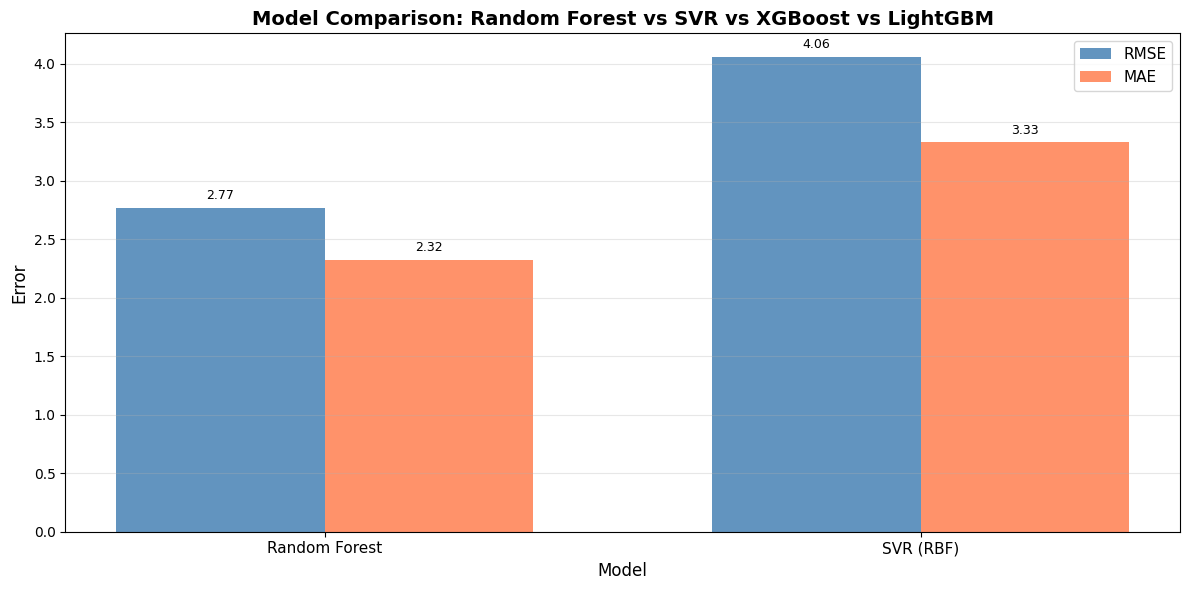

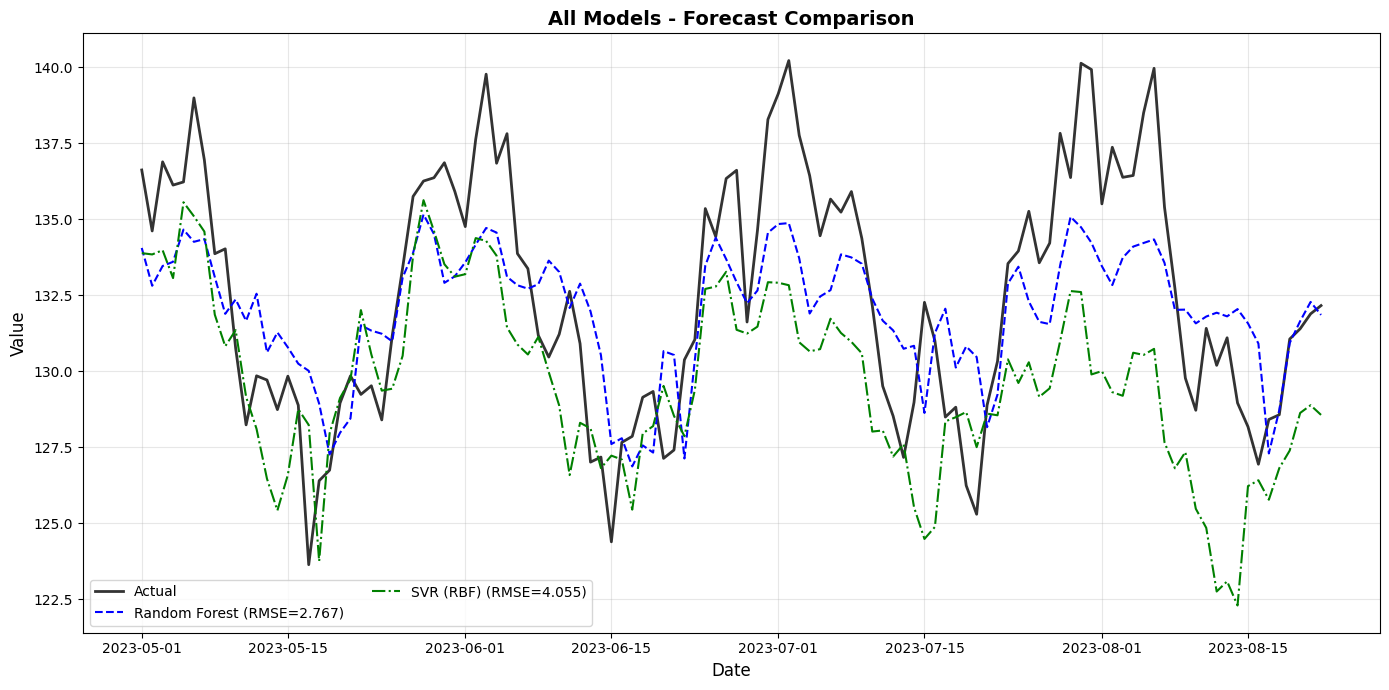

In [ ]:
print("\n" + "-" * 60)
print("GENERATING PLOTS")
print("-" * 60)

# 9a. XGBoost predictions
if y_pred_xgb is not None:
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.plot(y_test.index, y_test.values, 'b-', linewidth=2, alpha=0.8, label='Actual')
    ax.plot(y_test.index, y_pred_xgb, 'r-', linewidth=2, alpha=0.7, label='XGBoost Forecast')
    ax.fill_between(y_test.index,
                    y_pred_xgb - rmse_xgb, y_pred_xgb + rmse_xgb,
                    color='red', alpha=0.1, label=f'+/- RMSE ({rmse_xgb:.2f})')
    ax.set_title('XGBoost - Time Series Forecast', fontsize=14, fontweight='bold')
    ax.set_xlabel('Date', fontsize=12)
    ax.set_ylabel('Value', fontsize=12)
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'xgboost_forecast.png'), dpi=150)
    print("Saved: xgboost_forecast.png")

# 9b. Feature importance (gain)
if xgb_model is not None:
    fig, ax = plt.subplots(figsize=(10, 7))
    top_n = 15
    top_feats = importance_series.head(top_n)
    ax.barh(range(len(top_feats)), top_feats.values)
    ax.set_yticks(range(len(top_feats)))
    ax.set_yticklabels(top_feats.index)
    ax.invert_yaxis()
    ax.set_xlabel('Gain (improvement in squared error)', fontsize=12)
    ax.set_title(f'Top {top_n} Feature Importance (XGBoost - Gain)', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3, axis='x')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'xgboost_feature_importance.png'), dpi=150)
    print("Saved: xgboost_feature_importance.png")

# 9c. Model comparison bar chart
fig, ax = plt.subplots(figsize=(12, 6))
model_names = list(all_results.keys())
rmse_vals = [all_results[n]['RMSE'] for n in model_names]
mae_vals = [all_results[n]['MAE'] for n in model_names]

x = np.arange(len(model_names))
width = 0.35
bars1 = ax.bar(x - width / 2, rmse_vals, width, label='RMSE',
               color='steelblue', alpha=0.85)
bars2 = ax.bar(x + width / 2, mae_vals, width, label='MAE',
               color='coral', alpha=0.85)

ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('Error', fontsize=12)
ax.set_title('Model Comparison: Random Forest vs SVR vs XGBoost vs LightGBM',
             fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(model_names, fontsize=11)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, axis='y')

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'model_comparison.png'), dpi=150)
print("Saved: model_comparison.png")

# 9d. All model forecasts on same plot
fig, ax = plt.subplots(figsize=(14, 7))
ax.plot(y_test.index, y_test.values, 'k-', linewidth=2, label='Actual', alpha=0.8)

colors = {'Random Forest': 'blue', 'SVR (RBF)': 'green',
          'XGBoost': 'red', 'LightGBM': 'orange'}
styles = {'Random Forest': '--', 'SVR (RBF)': '-.',
           'XGBoost': ':', 'LightGBM': (0, (3, 1, 1, 1))}

forecasts = {
    'Random Forest': y_pred_rf,
    'SVR (RBF)': y_pred_svr,
}

if y_pred_xgb is not None:
    forecasts['XGBoost'] = y_pred_xgb
if lgb_available:
    forecasts['LightGBM'] = y_pred_lgb

for name, pred in forecasts.items():
    ax.plot(y_test.index, pred, linestyle=styles.get(name, '--'),
            color=colors.get(name, 'gray'), linewidth=1.5,
            label=f"{name} (RMSE={all_results[name]['RMSE']:.3f})")

ax.set_title('All Models - Forecast Comparison', fontsize=14, fontweight='bold')
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Value', fontsize=12)
ax.legend(fontsize=10, ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'all_models_forecast.png'), dpi=150)
print("Saved: all_models_forecast.png")


## 10. SUMMARY


In [ ]:
print("\n" + "=" * 60)
print("SUMMARY")
print("=" * 60)
print("Individual model performance:")
for name, res in sorted(all_results.items(), key=lambda x: x[1]['RMSE']):
    print(f"  {name:15s}: RMSE={res['RMSE']:.4f}, MAE={res['MAE']:.4f}")

print(f"\nBest model: {best_model_name}")

if xgb_model is not None:
    print("\nTop 5 XGBoost features:")
    for feat, imp in importance_series.head(5).items():
        print(f"  {feat:20s}: {imp:.4f}")

print("\nKey takeaways:")
print("  1. XGBoost typically outperforms RF and SVR for complex time series")
print("  2. Early stopping prevents overfitting (uses validation set)")
print("  3. Gain-based importance shows which features drive predictions")
print("  4. LightGBM is faster but XGBoost often generalizes better on smaller data")
print("  5. Feature engineering remains critical even for tree-based models")




SUMMARY
Individual model performance:
  Random Forest  : RMSE=2.7668, MAE=2.3199
  SVR (RBF)      : RMSE=4.0555, MAE=3.3266

Best model: Random Forest

Top 5 XGBoost features:
  lag_1               : 171.2727
  lag_30              : 79.6297
  rmean_30            : 43.4019
  is_weekend          : 24.0972
  day_of_week         : 19.0890

Key takeaways:
  1. XGBoost typically outperforms RF and SVR for complex time series
  2. Early stopping prevents overfitting (uses validation set)
  3. Gain-based importance shows which features drive predictions
  4. LightGBM is faster but XGBoost often generalizes better on smaller data
  5. Feature engineering remains critical even for tree-based models


---
## Part-4 Complete!

All lessons finished successfully.
